In [40]:
import pandas as pd
import numpy as np

# Set random seed for consistency
np.random.seed(42)

# Number of samples you want
num_samples = 300

# Generate synthetic features
age = np.random.randint(30, 85, num_samples)
gender = np.random.choice(["Male", "Female"], num_samples)
bilirubin = np.random.uniform(0.3, 8.0, num_samples)         # mg/dL
alk_phosphate = np.random.uniform(60, 600, num_samples)      # U/L
gallstones = np.random.choice([0, 1], num_samples)           # 1 = yes
abdominal_pain = np.random.choice([0, 1], num_samples)
jaundice = np.random.choice([0, 1], num_samples)

# Create cancer probability based on risk factors
cancer_probability = (
    (age > 55).astype(int) * 0.2 +
    (bilirubin > 2).astype(int) * 0.3 +
    (alk_phosphate > 300).astype(int) * 0.2 +
    gallstones * 0.2 +
    jaundice * 0.3
)

# Convert probability to cancer label
cancer = (cancer_probability + np.random.uniform(0, 0.3, num_samples) > 0.5).astype(int)

# Combine into a DataFrame
df = pd.DataFrame({
    "Age": age,
    "Gender": gender,
    "Bilirubin": bilirubin.round(2),
    "Alkaline_Phosphatase": alk_phosphate.round(2),
    "Gallstones": gallstones,
    "Abdominal_Pain": abdominal_pain,
    "Jaundice": jaundice,
    "Gallbladder_Cancer": cancer
})

# Save CSV
df.to_csv("gallbladder_synthetic.csv", index=False)

print("Synthetic dataset created: gallbladder_synthetic.csv")
import os
from IPython.display import FileLink

df.to_csv("gallbladder_synthetic.csv",index=False)
FileLink("gallbladder_synthetic.csv")

Synthetic dataset created: gallbladder_synthetic.csv


c:\Users\User\Downloads\gallbladder_synthetic.csv

In [41]:
import pandas as pd 

df=pd.read_csv("gallbladder_synthetic.csv")

X = df.drop("Gallbladder_Cancer",axis=1 )
y = df["Gallbladder_Cancer"]

print(X.head())
print(y.head())





   Age  Gender  Bilirubin  Alkaline_Phosphatase  Gallstones  Abdominal_Pain  \
0   68    Male       2.93                464.79           1               0   
1   81  Female       1.01                 76.45           1               1   
2   58  Female       1.03                528.30           0               0   
3   44    Male       2.70                251.24           0               1   
4   72    Male       7.84                274.47           1               1   

   Jaundice  
0         0  
1         1  
2         0  
3         0  
4         1  
0    1
1    1
2    0
3    0
4    1
Name: Gallbladder_Cancer, dtype: int64


In [42]:
import pandas as pd 
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

#Load dataset
df = pd.read_csv("gallbladder_synthetic.csv")

#convert text columns to numbers 
df = pd.get_dummies(df,
drop_first=True)

#features and Target
X = df.drop("Gallbladder_Cancer", 
axis=1)
y = df["Gallbladder_Cancer"]

#Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2,
random_state=42
)

#Train model
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

#predict
y_pred = model.predict(X_test)

#Accuracy
print("Accuracy:",
accuracy_score(y_test, y_pred))


Accuracy: 0.9833333333333333


In [43]:
print(df.columns)

Index(['Age', 'Bilirubin', 'Alkaline_Phosphatase', 'Gallstones',
       'Abdominal_Pain', 'Jaundice', 'Gallbladder_Cancer', 'Gender_Male'],
      dtype='object')


In [44]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

#Create model
RandomForestClassifier(random_state=42)

#Train model
rf.fit(X_train, y_train)

#predict
rf.pred = rf.predict(X_test)

#accuracy
print("Random Forest Accuracy:",
accuracy_score(y_test, rf_pred))


Random Forest Accuracy: 0.9833333333333333


In [45]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

from sklearn.metrics import accuracy_score
print("Random Forest Accuracy:",accuracy_score(y_test, rf_pred))

Random Forest Accuracy: 0.9833333333333333


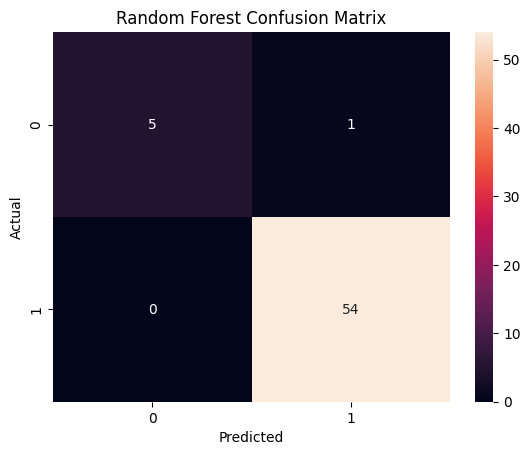

In [47]:
#confusion matrix
from sklearn.metrics import confusion_matrix
import seaborn as sns 
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, rf_pred)

sns.heatmap(cm, annot=True, fmt='d')
plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()



In [48]:
#classification Report
from sklearn.metrics import classification_report
print(classification_report(y_test,rf_pred))

              precision    recall  f1-score   support

           0       1.00      0.83      0.91         6
           1       0.98      1.00      0.99        54

    accuracy                           0.98        60
   macro avg       0.99      0.92      0.95        60
weighted avg       0.98      0.98      0.98        60



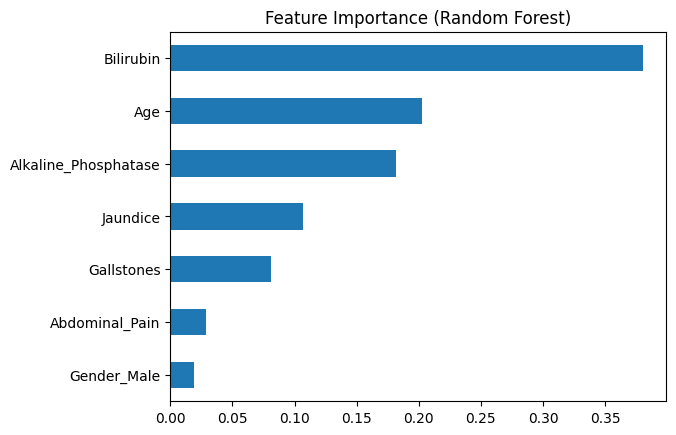

In [49]:
import pandas as pd
import matplotlib.pyplot as plt

importance = pd.Series(rf.feature_importances_,index=X.columns )
importance.sort_values().plot(kind='barh')
plt.title("Feature Importance (Random Forest)")
plt.show()

In [32]:
#Cross validation
from sklearn.model_selection import cross_val_score
scores = cross_val_score(rf, X, y, cv=5)

print("Cross Validation Scores:", scores)
print("Average CV score:", scores.mean())

Cross Validation Scores: [0.93333333 0.98333333 0.93333333 0.95       0.98333333]
Average CV score: 0.9566666666666667


In [50]:
#standardScaler
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2,
random_state=42
)

c:\Users\User\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


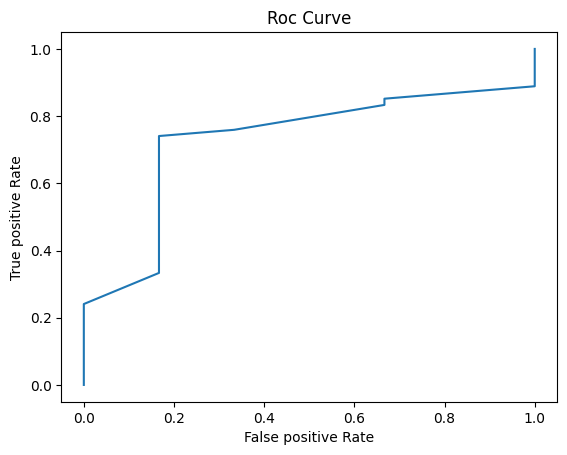

AUC Score: 0.728395061728395


In [51]:
#ROC Curve
from sklearn.metrics import roc_curve,auc

y_prob = rf.predict_proba(X_test)[:,1]

fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

plt.plot(fpr, tpr)
plt.xlabel("False positive Rate")
plt.ylabel("True positive Rate")
plt.title("Roc Curve")
plt.show()

print("AUC Score:", roc_auc)

In [38]:
#Hyperparameter tuning

from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 5, 10]
}

grid = GridSearchCV(RandomForestClassifier(random_state=42),
                                                               param_grid, 
                                                               cv=5)
grid.fit(X_train, y_train)

print("Best parameters:",grid.best_params_)

Best parameters: {'max_depth': None, 'n_estimators': 50}


In [39]:
#Production level

import joblib
joblib.dump(rf,"liver_model.pkl")

['liver_model.pkl']